In [52]:
#load the two datasets
from pathlib import Path
import pandas as pd

data_dir = Path.cwd() / 'data'
file_path_obama = data_dir / 'Obama_Speeches.csv'
file_path_trump = data_dir / 'Trump_Labeled_Combined_Rev_Speeches_Final_9-24-2024.csv'

full_obama = pd.read_csv(file_path_obama)
full_trump = pd.read_csv(file_path_trump)

#sort original dataset by date

full_trump['date'] = pd.to_datetime(full_trump['date'])
full_trump = (full_trump.sort_values('date').reset_index(drop=True))

full_obama['date'] = pd.to_datetime(full_obama['date'])
full_obama = (full_obama.sort_values('date').reset_index(drop=True))

obama = pd.concat([full_obama.iloc[:50], full_obama.iloc[-50:]]).reset_index(drop=True) #removing outliers
trump = pd.concat([full_trump.iloc[7:57], full_trump.iloc[-50:]]).reset_index(drop=True)

#(sub 1.2 working with data)

In [53]:
#extract the relevant columns/data and change the order of the columns
trump = trump[['date', 'title','transcript', 'word_count', 'stop_word_count', 'non_stopwords']].copy()
#change order of columns
obama = obama[['date', 'title', 'transcript']]

#(sub 1.3 working with data)

## Visualisering

In [54]:
#add 'word_count', 'stop_word_count', 'non_stopwords' to the obama dataset
from gensim.utils import simple_preprocess
from nltk.corpus import stopwords

#tokenize, lowercase, removes punctuation, count the words
obama['word_count'] = [
    len(simple_preprocess(speech, min_len=1, max_len=100))
    for speech in obama['transcript']]

#count the stopwords
stop_words = stopwords.words('english')
obama['stop_word_count'] = [
    len([word for word in simple_preprocess(speech, min_len=1, max_len=100)
         if word in stop_words])
    for speech in obama['transcript']]

#extract non_stopwords
obama['non_stopwords'] = [
    ' '.join([word for word in simple_preprocess(speech)
              if word not in stop_words])
    for speech in obama['transcript']]


print(len(trump))
display(trump.head())

display(len(obama))
display(obama.head())

#(workshop nlp, nlp_canvas.ipynb)

100


,date,title,transcript,word_count,stop_word_count,non_stopwords
0,2019-07-05,donald-trump-4th-of-july-event-speech-transcri...,utah and omaha beaches. every coastguardsman i...,2131,906,utah omaha beaches every coastguardsman truste...
1,2019-07-17,donald-trump-maga-event-speech-transcript-nort...,thank you very much. thank you. thank you. tha...,10925,5348,thank much thank thank thank greenville north ...
2,2019-07-23,donald-trump-speech-transcript-turning-point-u...,good builder. he loved to build houses. he was...,12123,6190,good builder loved build houses good builder l...
3,2019-07-26,donald-trump-hannity-interview-transcript-trum...,"well, i think people learned a lot yesterday w...",2719,1421,well think people learned lot yesterday watchi...
4,2019-07-31,donald-trump-speech-transcript-in-jamestown-vi...,it’s a true privilege to be back in the great ...,2136,986,true privilege back great commonwealth virgini...


100

,date,title,transcript,word_count,stop_word_count,non_stopwords
0,2009-01-21,President Barack Obama's Inaugural Address,My fellow citizens: I stand here today humbled...,2427,1247,fellow citizens stand today humbled task us gr...
1,2009-01-21,Remarks of the President in Welcoming Senior S...,"Hello, everybody. Please be seated. Still gett...",1546,857,hello everybody please seated still getting us...
2,2009-01-21,Remarks of the President in Welcoming Senior S...,THE PRESIDENT: For the senior staff.\n\n\n\nTH...,34,14,president senior staff president yes number ca...
3,2009-01-23,Remarks by the President Before the Bipartisan...,"Well, it is great to see you. We are here toge...",551,317,well great see together couple weeks first mee...
4,2009-01-24,WEEKLY ADDRESS: President Barack Obama Discuss...,We begin this year and this Administration in ...,819,389,begin year administration midst unprecedented ...


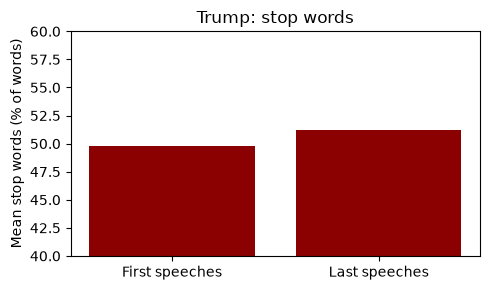

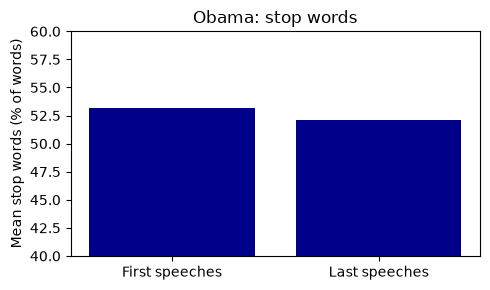

In [55]:
#visualize and compare speeches
import matplotlib.pyplot as plt

#calculate stopwords as a percentage of all words
trump['stop_word_rate'] = (trump['stop_word_count'] / trump['word_count'] * 100)
obama['stop_word_rate'] = (obama['stop_word_count'] / obama['word_count'] * 100)

#trumps first five vs last five speeches
trump_rates = [trump['stop_word_rate'].iloc[:50].mean(),
               trump['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       trump_rates,
       color=['darkred'])
ax.set_title('Trump: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(40,60)
plt.tight_layout()
plt.show()

#obama first five vs last five speeches
obama_rates = [obama['stop_word_rate'].iloc[:50].mean(),
               obama['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       obama_rates,
       color=['darkblue'])
ax.set_title('Obama: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(40,60)
plt.tight_layout()
plt.show()

#(sub 1.4 visualisations)

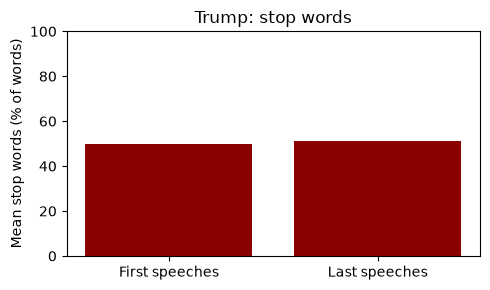

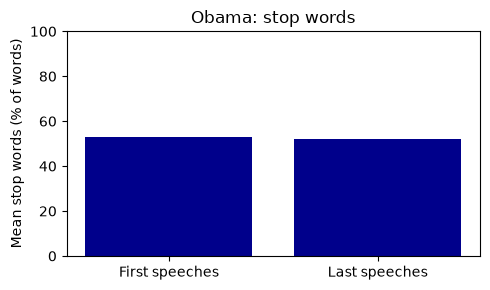

In [56]:
#visualize and compare speeches
import matplotlib.pyplot as plt

#calculate stopwords as a percentage of all words
trump['stop_word_rate'] = (trump['stop_word_count'] / trump['word_count'] * 100)
obama['stop_word_rate'] = (obama['stop_word_count'] / obama['word_count'] * 100)

#trumps first five vs last five speeches
trump_rates = [trump['stop_word_rate'].iloc[:50].mean(),
               trump['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       trump_rates,
       color=['darkred'])
ax.set_title('Trump: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()

#obama first five vs last five speeches
obama_rates = [obama['stop_word_rate'].iloc[:50].mean(),
               obama['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       obama_rates,
       color=['darkblue'])
ax.set_title('Obama: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()

#(sub 1.4 visualisations)

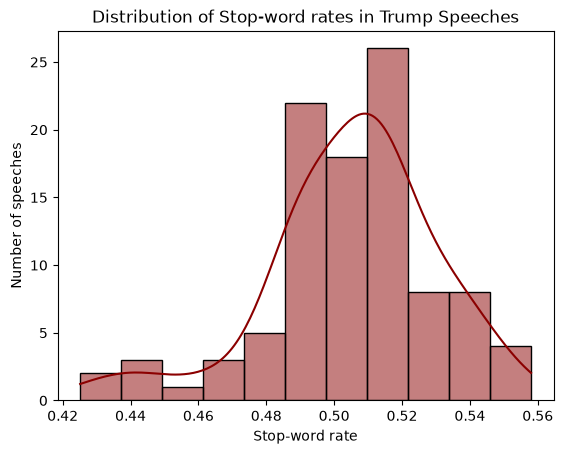

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

stop_word_rate_trump = trump['stop_word_count'] / trump['word_count']

sns.histplot(
    x=stop_word_rate_trump,
    color = 'darkred',
    kde=True
)

plt.xlabel('Stop-word rate')
plt.ylabel('Number of speeches')
plt.title('Distribution of Stop-word rates in Trump Speeches')
plt.show()

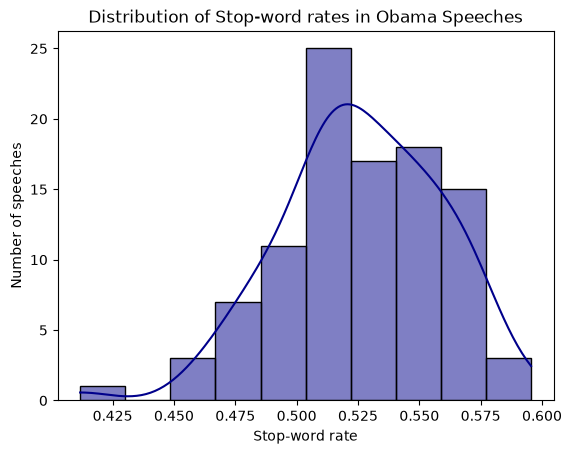

In [58]:
stop_word_rate_obama = obama['stop_word_count'] / obama['word_count']

sns.histplot(
    x=stop_word_rate_obama,
    color = 'darkblue',
    kde=True
)

plt.xlabel('Stop-word rate')
plt.ylabel('Number of speeches')
plt.title('Distribution of Stop-word rates in Obama Speeches')
plt.show()

<Axes: xlabel='date', ylabel='None'>

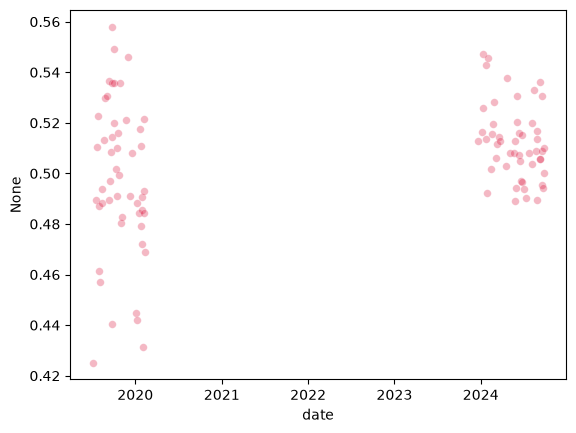

In [59]:
sns.scatterplot(data=trump, x='date', y=stop_word_rate_trump,
                color= 'crimson', s=30, alpha=0.3)

<Axes: xlabel='date', ylabel='None'>

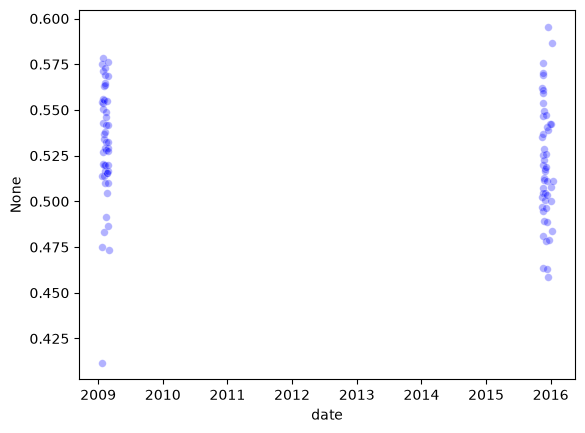

In [60]:
sns.scatterplot(data=obama, x='date', y=stop_word_rate_obama,
                color= 'blue', s=30, alpha=0.3)

In [61]:
print(obama[if 'stop_word' =>0.42])

SyntaxError: invalid syntax (1802946068.py, line 1)